## Unsupervised (clustering)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
X,y_true = make_blobs(n_samples = 500, centers = 3, cluster_std = 4, random_state = 42)

In [3]:
df = pd.DataFrame(X, columns= ['Feature_1', 'Feature_2'])

In [4]:
df

,Feature_1,Feature_2
0,-2.282534,-9.692815
1,-6.147668,1.755990
2,13.399091,-1.260023
3,-4.077630,3.160226
4,9.444735,0.340868
...,...,...
495,-1.282205,-3.181575
496,-2.817604,10.378894
497,3.296740,8.649256
498,-8.970519,-2.684073


In [5]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(df)

In [6]:
inertia = []
K_range = range(1, 11)

In [7]:
for k in K_range:
    kmeans = KMeans(n_clusters = k, random_state = 42)
    kmeans.fit(x_scaled)
    inertia.append(kmeans.inertia_)

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

In [8]:
inertia

[999.9999999999991,
 528.8064432605648,
 294.4377068678187,
 250.45524696534443,
 216.88110656982602,
 185.27440675195902,
 156.70879996290444,
 135.62603453115247,
 129.10396348239811,
 119.94101297104991]

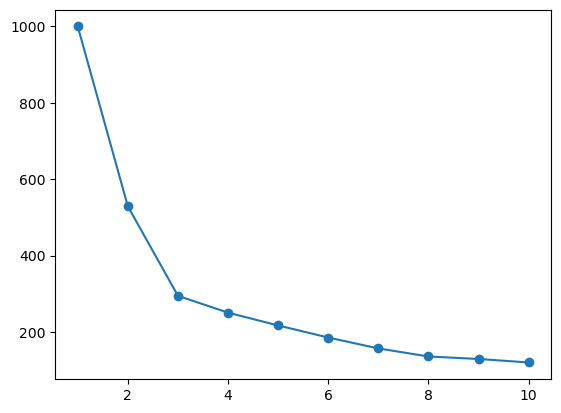

In [9]:
plt.plot(K_range, inertia, marker = 'o')

In [10]:
kmeans_final = KMeans(n_clusters = 6, random_state = 42)

In [11]:
cluster_labels = kmeans_final.fit_predict(x_scaled)

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


In [12]:
df['cluster'] = cluster_labels

<Axes: xlabel='Feature_1', ylabel='Feature_2'>

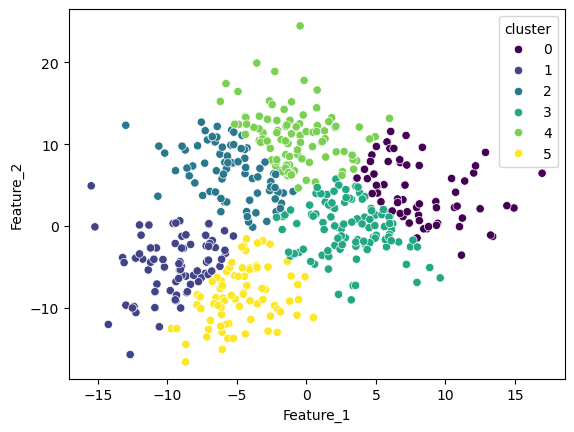

In [13]:
sns.scatterplot(x= df['Feature_1'],
                y = df['Feature_2'],
                hue = df['cluster'],
                palette = 'viridis')

In [14]:
from sklearn.datasets import make_moons

In [15]:
X, y_true = make_moons(n_samples = 500, noise = 0.05, random_state = 42)

In [16]:
from sklearn.cluster import KMeans, DBSCAN
df = pd.DataFrame(X, columns = ['Feature_1', 'Feature_2'])

In [17]:
scaler = StandardScaler()

In [18]:
X_scaled = scaler.fit_transform(df)

In [19]:
kmeans = KMeans(n_clusters = 2, random_state = 42)
kmeans_labels = kmeans.fit_predict(X_scaled)

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


In [20]:
df['kmeans_clusters'] = kmeans_labels

<Axes: xlabel='Feature_1', ylabel='Feature_2'>

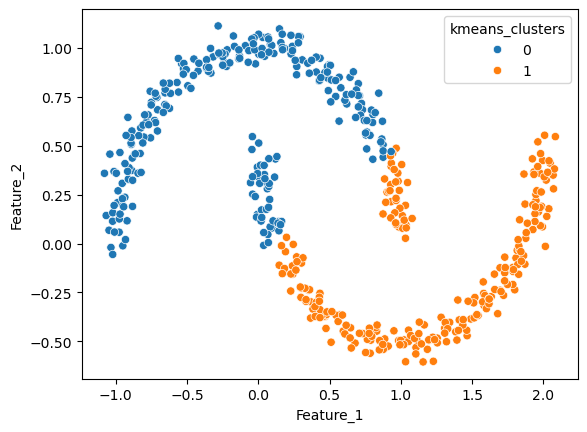

In [21]:
sns.scatterplot(x = df['Feature_1'],
                y = df['Feature_2'],
                hue = df['kmeans_clusters'], 
                palette = 'tab10')

In [25]:
dbscan = DBSCAN(eps = 0.3, min_samples = 5)
dbscan_labels = dbscan.fit_predict(X_scaled)

In [26]:
df['dbscan_cluster'] = dbscan_labels

In [28]:
df

,Feature_1,Feature_2,kmeans_clusters,dbscan_cluster
0,0.830586,-0.447733,1,0
1,0.701678,0.816918,0,1
2,1.022080,-0.492571,1,0
3,-0.316765,0.953438,0,1
4,0.293226,1.057185,0,1
...,...,...,...,...
495,0.239754,0.985462,0,1
496,0.072145,0.184834,0,0
497,0.590273,-0.365577,1,0
498,1.619465,-0.283658,1,0


<Axes: xlabel='Feature_1', ylabel='Feature_2'>

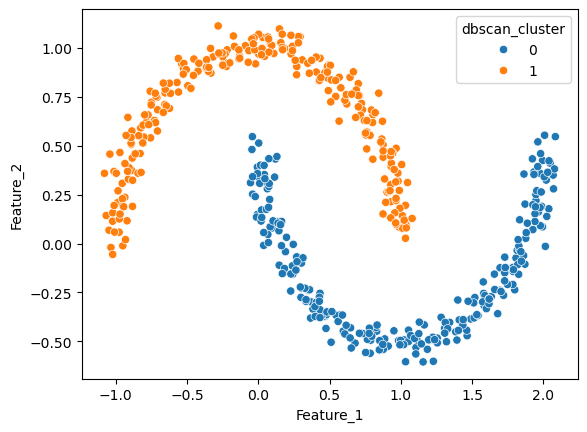

In [29]:
sns.scatterplot(x = df['Feature_1'], y = df['Feature_2'],
                hue = df['dbscan_cluster'], palette = 'tab10')